<a href="https://colab.research.google.com/github/seyma26n/GROUP38_CENG313/blob/main/notebooks/Assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Image Matching Challenge 2025

## Drive Connection

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

data_path = "/content/drive/MyDrive/CENG313_Project/data"

labels_path = os.path.join(data_path, "train_labels.csv")

stairs_folder = os.path.join(data_path, "train", "stairs")

haiper_folder = os.path.join(data_path, "train", "imc2023_haiper")

In [ ]:
print("CSV exists:", os.path.isfile(labels_path))

print("Stairs folder exists:", os.path.isdir(stairs_folder))

print("Haiper folder exists:", os.path.isdir(haiper_folder))

CSV exists: True
Stairs folder exists: True
Haiper folder exists: True


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of examining and understanding a dataset before applying machine learning models. Its main purpose is to identify patterns, distributions, and potential data quality issues through statistical analysis and visualization.

In this project, EDA is performed on the Image Matching Challenge 2025 dataset to better understand its structure and characteristics. The analysis consists of seven sections:

1. **Dataset Overview:** Examining the general structure and basic information of the dataset.
2. **Dataset Quality Check:** Checking for missing values, duplicate records, and data inconsistencies.
3. **Image Distribution Analysis:** Analyzing the distribution of images across datasets and scenes.
4. **Scene and Outlier Analysis:** Examining scene diversity and the distribution of outlier images.
5. **Image Resolution Analysis:** Investigating image dimensions, resolutions, and aspect ratios.
6. **Visual Similarity Analysis:** Comparing images from the same and different scenes to identify visual similarities and differences.
7. **Camera Pose Analysis:** Examining rotation and translation data and visualizing camera positions.

These analyses provide a better understanding of the dataset and help identify potential challenges for image matching, scene clustering, and camera pose estimation in the following stages of the project.

### Dataset Overview

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(labels_path)

# Dataset Overview

# ilk 5 satır
print("")
display(df.head())
print("---------------------------------------------------------")

# satır,sütun sayısı
print("Row, column numbers:")
print(df.shape)
print("---------------------------------------------------------")

# sütun isimleri
print("Column names - features: ")
print(df.columns)
print("---------------------------------------------------------")

# Veri tipleri
print("Data types:")
df.info()
print("---------------------------------------------------------")

# Toplam dataset sayısı
print("toplam dataset sayısı: ")
print(df["dataset"].nunique())
print("---------------------------------------------------------")

# Toplam farklı dataset-scene çifti sayısı
print("dataset-scene çifti sayısı: ")
print(df[["dataset", "scene"]].drop_duplicates().shape[0])
print("---------------------------------------------------------")

# Train dosyasında toplam 13 adet dataset, tüm bu datasetlerin içerisinde toplam 1945 adet görsel bulunur.
# 35 adet scene-dataset çifti bulunur.

,dataset,scene,image,rotation_matrix,translation_vector
0,imc2023_haiper,fountain,fountain_image_116.png,0.122655949;0.947713775;-0.294608417;0.1226706...,0.093771314;-0.803560988;2.062001533
1,imc2023_haiper,fountain,fountain_image_108.png,0.474305910;0.359108654;-0.803787832;0.2888416...,0.358946647;-0.797557548;1.910906929
2,imc2023_haiper,fountain,fountain_image_101.png,0.565115476;-0.138485064;-0.813305838;0.506678...,0.146922468;-0.981392596;2.009002852
3,imc2023_haiper,fountain,fountain_image_082.png,-0.308320392;-0.794654112;0.522937261;0.948141...,0.206413831;-1.174321103;3.667167680
4,imc2023_haiper,fountain,fountain_image_071.png,-0.569002830;-0.103808175;0.815757098;0.778745...,-0.015140892;-1.334052012;3.488936597


---------------------------------------------------------
Row, column numbers:
(1945, 5)
---------------------------------------------------------
Column names - features: 
Index(['dataset', 'scene', 'image', 'rotation_matrix', 'translation_vector'], dtype='object')
---------------------------------------------------------
Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945 entries, 0 to 1944
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   dataset             1945 non-null   object
 1   scene               1945 non-null   object
 2   image               1945 non-null   object
 3   rotation_matrix     1945 non-null   object
 4   translation_vector  1945 non-null   object
dtypes: object(5)
memory usage: 76.1+ KB
---------------------------------------------------------
toplam dataset sayısı: 
13
---------------------------------------------------------
dataset-scene çifti sayısı: 
34
-----

### Dataset Quality Check

In [ ]:
# Dataset Quality Check --> missing value, dublicated value ect.
# Eksik değer sayıları
print("eksik değerlerin sayıları: ")
print(df.isnull().sum())
print("---------------------------------------------")

# Tamamen aynı olan satırların sayısı
print("tamamen aynı olan satırların sayısı :")
print(df.duplicated().sum())
print("---------------------------------------------")

# Aynı dataset içerisinde tekrarlanan görüntü kayıtları
print(" Aynı dataset içerisinde tekrarlanan görüntü kayıtları: ")
print(df.duplicated(subset=["dataset", "image"]).sum())

# Bu kısımda yapılan analizler, kullanılan datsetteki eksik veri, tekrarlayan veri gibi hataları yakalamaya yarar.
# Ancak biz hazır dataset kullandığımız için bu analizler sonucunda çok fazla hata ile karşılaşmayı beklemiyoruz

eksik değerlerin sayıları: 
dataset               0
scene                 0
image                 0
rotation_matrix       0
translation_vector    0
dtype: int64
---------------------------------------------
tamamen aynı olan satırların sayısı :
0
---------------------------------------------
 Aynı dataset içerisinde tekrarlanan görüntü kayıtları: 
0


### Image Distrubution Analysis

 Dataset başına düşen görüntü sayısı :
 


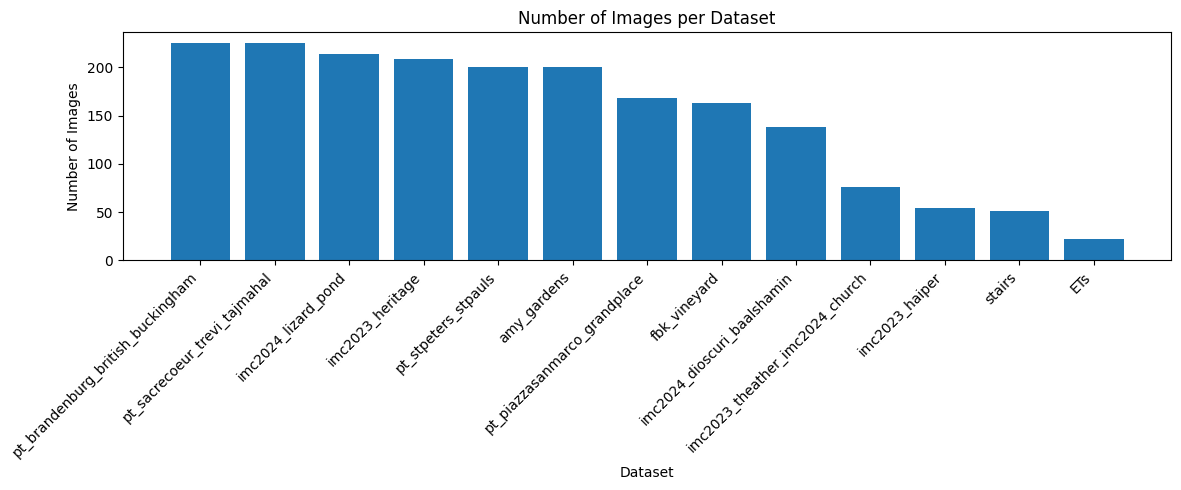

 
---------------------------------------------------------------------------------
---------------------------------------------------------------------------------
Scene başına düşen görüntü sayısı


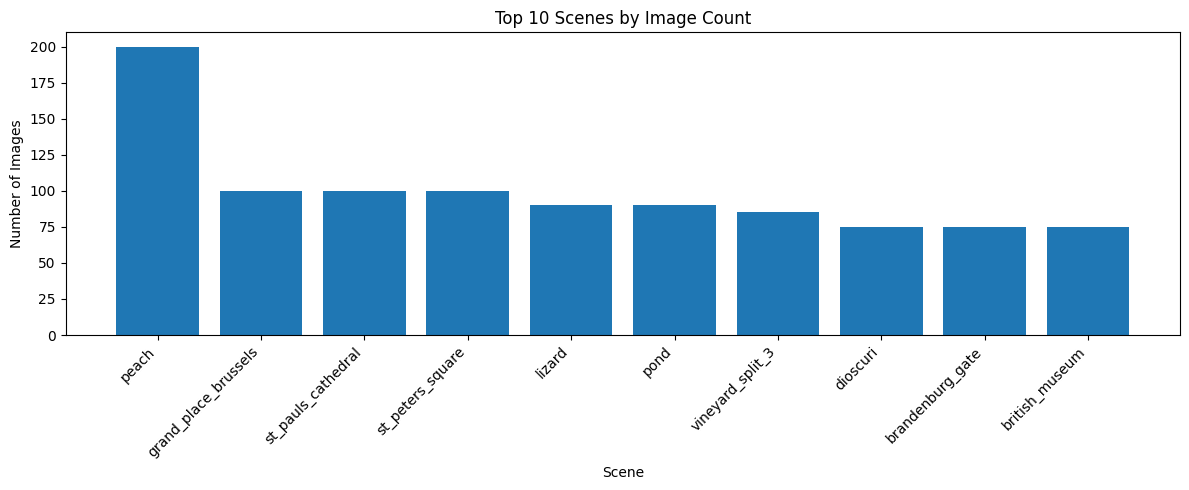

---------------------------------------------------------------------------------
---------------------------------------------------------------------------------


,dataset,scene,Image Count
3,amy_gardens,peach,200
25,pt_piazzasanmarco_grandplace,grand_place_brussels,100
30,pt_stpeters_stpauls,st_pauls_cathedral,100
31,pt_stpeters_stpauls,st_peters_square,100
19,imc2024_lizard_pond,lizard,90


,dataset,scene,Image Count
2,ETs,outliers,3
0,ETs,ET,9
1,ETs,another_ET,10
7,imc2023_haiper,bike,15
8,imc2023_haiper,chairs,16


---------------------------------------------------------------------------------
---------------------------------------------------------------------------------
 
Özet Tablo: 
Mean: 57.205882352941174
Median: 55.5
Minimum: 3
Maximum: 200
Standard Deviation: 38.827340735515236


In [ ]:
# Image Distrubution Analysis

# Grafik oluşturmak için matplotlib kütüphanesini import ediyoruz
import matplotlib.pyplot as plt

# Dataset başına düşen görüntü sayısı
print(" Dataset başına düşen görüntü sayısı :")
print(" ")

dataset_counts = df["dataset"].value_counts().reset_index()

dataset_counts.columns = ["Dataset", "Image Count"]

# Tablo görünümü
#display(dataset_counts)

# Grafik görünümü
plt.figure(figsize=(12, 5))

plt.bar(
    dataset_counts["Dataset"],
    dataset_counts["Image Count"]
)

plt.title("Number of Images per Dataset")
plt.xlabel("Dataset")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
print(" ")
print("---------------------------------------------------------------------------------")
print("---------------------------------------------------------------------------------")

print("Scene başına düşen görüntü sayısı")
# Scene başına düşen görüntü sayısı
scene_counts = (
    df.groupby(["dataset", "scene"])
    .size()
    .reset_index(name="Image Count")
)

# Tablo görünümü
#display(scene_counts)

# Grafik görünümü
# Yer kalabalığını önlemek için en fazla görsel içeren 10 scene ile bir grafik oluşturuyoruz
top_scenes = scene_counts.nlargest(10, "Image Count")

plt.figure(figsize=(12, 5))

plt.bar(
    top_scenes["scene"],
    top_scenes["Image Count"]
)

plt.title("Top 10 Scenes by Image Count")
plt.xlabel("Scene")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("---------------------------------------------------------------------------------")
print("---------------------------------------------------------------------------------")

# En büyük ve en küçük sahneler

# En fazla görüntü içeren 5 sahne
display(scene_counts.nlargest(5, "Image Count"))

# En az görüntü içeren 5 sahne
display(scene_counts.nsmallest(5, "Image Count"))

print("---------------------------------------------------------------------------------")
print("---------------------------------------------------------------------------------")

# Özet tablo --> Mean, medyan, min, max değerleri
print(" ")
print("Özet Tablo: ")
counts = scene_counts["Image Count"]

print("Mean:", counts.mean())
print("Median:", counts.median())
print("Minimum:", counts.min())
print("Maximum:", counts.max())
print("Standard Deviation:", counts.std())

### Scene and Outliar Analysis

,dataset,Total_Images,Outlier_Count,Scene_Count,Outlier_Rate
0,ETs,22,3,2,13.64
1,amy_gardens,200,0,1,0.00
2,fbk_vineyard,163,0,3,0.00
3,imc2023_haiper,54,0,3,0.00
4,imc2023_heritage,209,61,3,29.19
5,imc2023_theather_imc2024_church,76,0,2,0.00
6,imc2024_dioscuri_baalshamin,138,24,2,17.39
7,imc2024_lizard_pond,214,34,2,15.89
8,pt_brandenburg_british_buckingham,225,0,3,0.00
9,pt_piazzasanmarco_grandplace,168,0,2,0.00


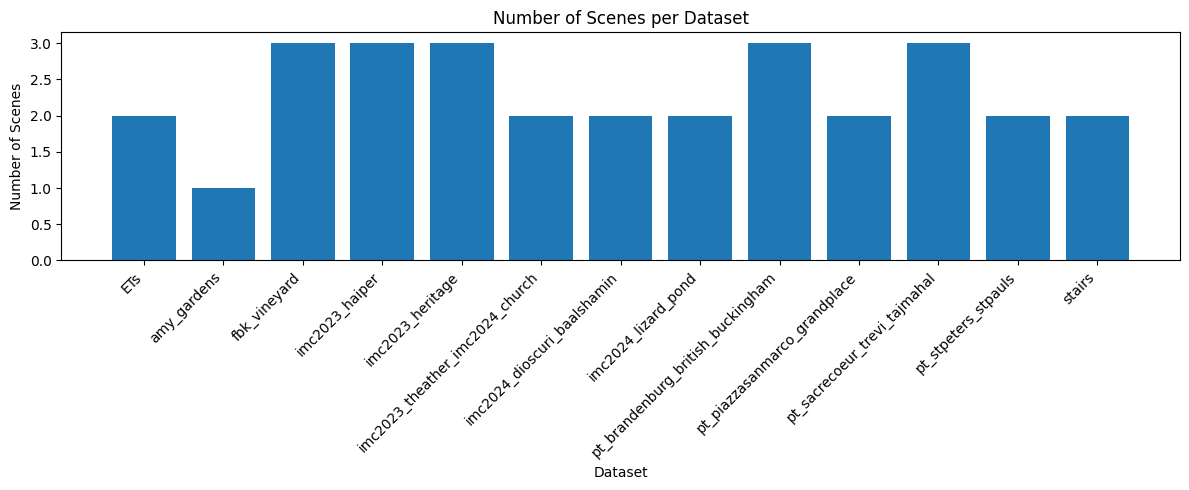

 
 
Single-scene datasets: 1
Multi-scene datasets: 12


In [ ]:
# Scene and Outliar Analysis --> dataset içindeki scene sayıları, outlier sayıları ve oranları

#önce outliar kontrolü için veriye outliar sütunu ekliyoruz
df["is_outlier"] = df["scene"] == "outliers"

valid_df = df[df["scene"] != "outliers"]

# Dataset başına genel bilgiler, tablo

summary = df.groupby("dataset").agg(
    Total_Images=("image", "count"),
    Outlier_Count=("is_outlier", "sum")
)

# Gerçek sahne sayılarını ekleme
# Datasetlere göre gruplama yapıp her data seti içindeki farklı scene etiketleri sayılır
summary["Scene_Count"] = (
    valid_df.groupby("dataset")["scene"].nunique()
)

# Outlier oranını hesaplama
summary["Outlier_Rate"] = (
    summary["Outlier_Count"] / summary["Total_Images"] * 100
)

# Tabloyu düzenleme
summary = summary.reset_index()

display(summary.round(2))

print(" ")
print(" ")

# Grafik görünümü
plt.figure(figsize=(12,5))

plt.bar(summary["dataset"], summary["Scene_Count"])

plt.title("Number of Scenes per Dataset")
plt.xlabel("Dataset")
plt.ylabel("Number of Scenes")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(" ")
print(" ")

# Tek sahneli ve çok sahneli datasetleri karşılaştırma
single_scene = (summary["Scene_Count"] == 1).sum()
multi_scene = (summary["Scene_Count"] > 1).sum()

print("Single-scene datasets:", single_scene)
print("Multi-scene datasets:", multi_scene)

# Outliar görüntülerin scene etiketlerinin "outliars" olduğunu bildiğimizden, scene etiketlerine göre ayıklama yaparak outliar görüntüleri ayırt edebiliyoruz

### Image Resolution Analysis

In [ ]:
# Select the datasets used for image resolution analysis
stairs_df = df[df["dataset"] == "stairs"].copy()

haiper_df = df[df["dataset"] == "imc2023_haiper"].copy()

In [ ]:
#Görüntünün boyutlarını hesaplama

from PIL import Image
import pandas as pd
import os

image_info = []

# Analyze images from the selected datasets
datasets = [
    (stairs_df, stairs_folder, "stairs"),
    (haiper_df, haiper_folder, "imc2023_haiper")
]

for dataset_df, folder, dataset_name in datasets:

    for image_name in dataset_df["image"]:

        image_path = os.path.join(folder, image_name)

        with Image.open(image_path) as img:
            width, height = img.size

        image_info.append({
            "Dataset": dataset_name,
            "Image": image_name,
            "Width": width,
            "Height": height,
            "Aspect Ratio": width / height,
            "Megapixels": (width * height) / 1_000_000
        })

resolution_df = pd.DataFrame(image_info)

display(resolution_df.head())

,Dataset,Image,Width,Height,Aspect Ratio,Megapixels
0,stairs,stairs_split_1_1710453963274.png,1280,1024,1.25,1.31072
1,stairs,stairs_split_1_1710453947066.png,1280,1024,1.25,1.31072
2,stairs,stairs_split_1_1710453985484.png,1280,1024,1.25,1.31072
3,stairs,stairs_split_1_1710453930259.png,1280,1024,1.25,1.31072
4,stairs,stairs_split_1_1710453901046.png,1280,1024,1.25,1.31072


In [ ]:
# Summary statistics of image dimensions
display(
    resolution_df[
        ["Width", "Height", "Aspect Ratio", "Megapixels"]
    ].describe().round(2)
)

,Width,Height,Aspect Ratio,Megapixels
count,105.00,105.00,105.00,105.00
mean,1362.29,1484.80,0.99,2.06
std,80.35,449.96,0.25,0.73
min,1280.00,1024.00,0.75,1.31
25%,1280.00,1024.00,0.75,1.31
50%,1440.00,1920.00,0.75,2.76
75%,1440.00,1920.00,1.25,2.76
max,1440.00,1920.00,1.25,2.76


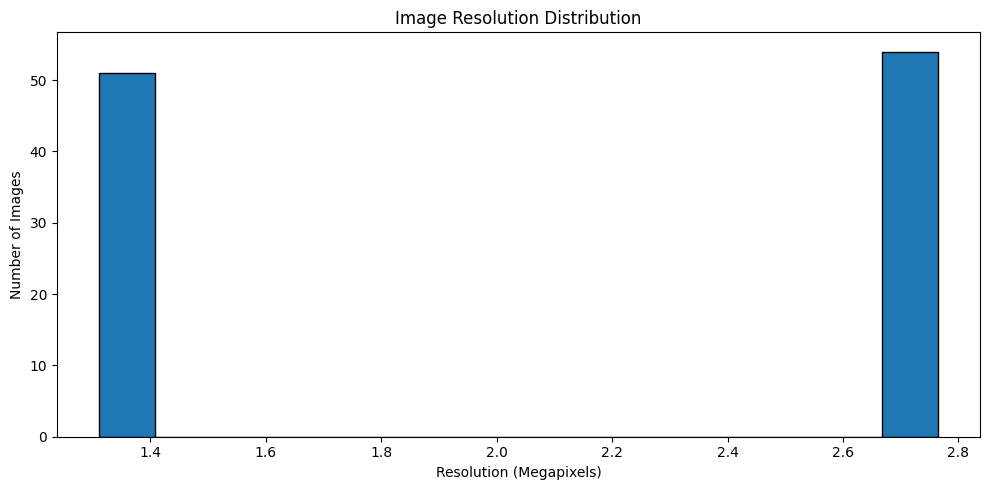

In [ ]:
# Resolution Distribution

plt.figure(figsize=(10, 5))

plt.hist(
    resolution_df["Megapixels"],
    bins=15,
    edgecolor="black"
)

plt.title("Image Resolution Distribution")
plt.xlabel("Resolution (Megapixels)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

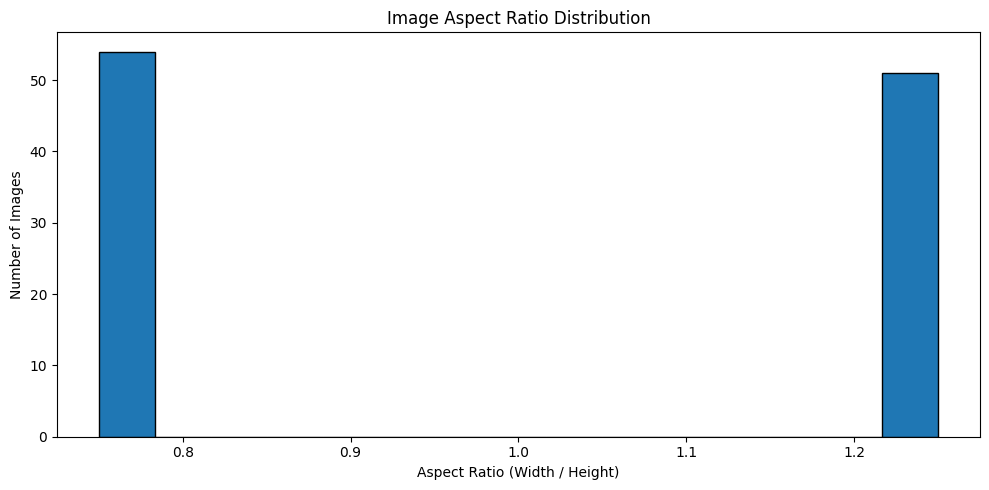

In [ ]:
# Aspect Ratio Distribution

plt.figure(figsize=(10, 5))

plt.hist(
    resolution_df["Aspect Ratio"],
    bins=15,
    edgecolor="black"
)

plt.title("Image Aspect Ratio Distribution")
plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

###  Visual Similarity Analysis

In [ ]:
# Check the scenes in the Haiper dataset
print(haiper_df["scene"].unique())

['fountain' 'bike' 'chairs']


In [ ]:
# Number of images per scene
display(haiper_df["scene"].value_counts())

,count
scene,
fountain,23
chairs,16
bike,15


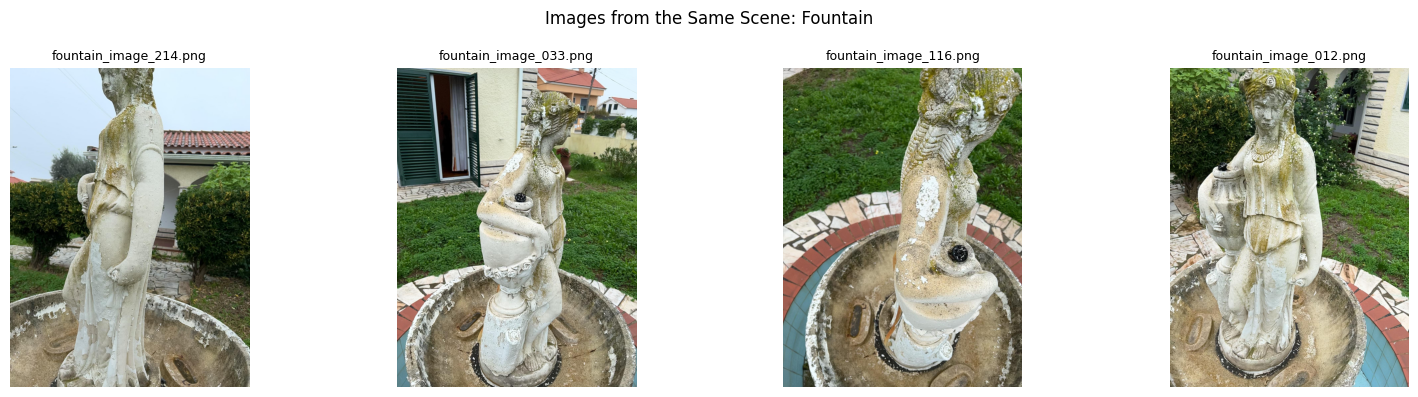

In [ ]:
# Aynı sahneye ait görüntüleri karşılaştırma

# Select 4 images from the same scene
same_scene = haiper_df[
    haiper_df["scene"] == "fountain"
].sample(n=4, random_state=42)

# Create the figure
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (_, row) in zip(axes, same_scene.iterrows()):

    image_path = os.path.join(
        haiper_folder,
        row["image"]
    )

    with Image.open(image_path) as img:
        ax.imshow(img)

    ax.set_title(row["image"], fontsize=9)
    ax.axis("off")

plt.suptitle("Images from the Same Scene: Fountain")
plt.tight_layout()
plt.show()

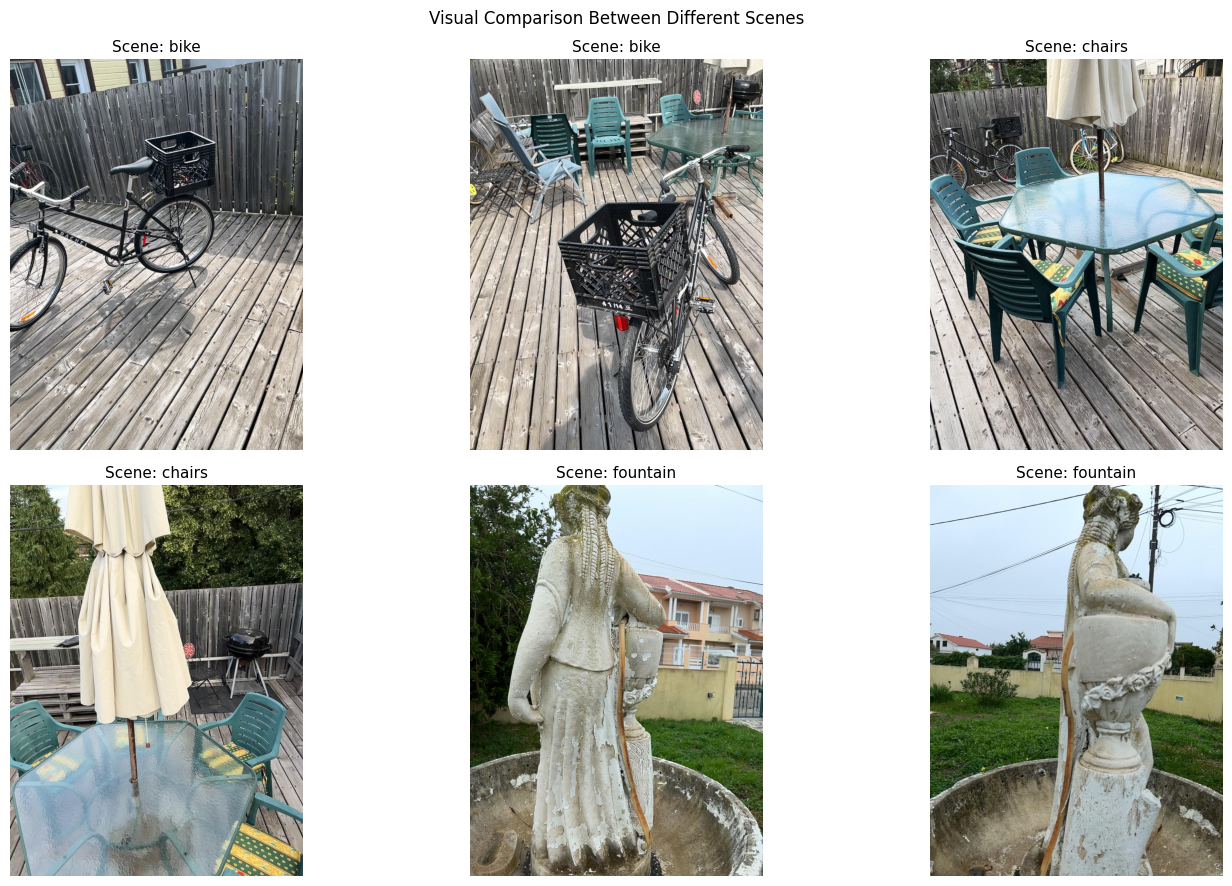

In [ ]:
# Farklı sahnelere ait görüntülerin karşılaştırılması

# Select 2 images from each scene
different_scenes = (
    haiper_df.groupby("scene", group_keys=False)
    .sample(n=2, random_state=42)
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (_, row) in zip(axes.flat, different_scenes.iterrows()):

    image_path = os.path.join(
        haiper_folder,
        row["image"]
    )

    with Image.open(image_path) as img:
        ax.imshow(img)

    ax.set_title(
        f"Scene: {row['scene']}",
        fontsize=11
    )

    ax.axis("off")

plt.suptitle("Visual Comparison Between Different Scenes")
plt.tight_layout()
plt.show()

In [ ]:
# Outliar görüntülerin incelenmesi

outlier_df = df[df["scene"] == "outliers"]

display(
    outlier_df["dataset"].value_counts()
)

,count
dataset,
imc2023_heritage,61
imc2024_lizard_pond,34
imc2024_dioscuri_baalshamin,24
ETs,3


### Camera Pose Analysis

In [ ]:
import numpy as np

# Check missing camera pose values
pose_summary = pd.DataFrame({
    "Total Images": [len(df)],
    "Missing Rotation": [df["rotation_matrix"].isna().sum()],
    "Missing Translation": [df["translation_vector"].isna().sum()]
})

display(pose_summary)

,Total Images,Missing Rotation,Missing Translation
0,1945,0,0


In [ ]:
# Check whether a pose field has the expected format
def valid_pose_format(value, expected_length):

    if pd.isna(value):
        return False

    try:
        values = np.array(
            [float(x) for x in str(value).split(";")]
        )

        return (
            len(values) == expected_length
            and np.isfinite(values).all()
        )

    except (ValueError, TypeError):
        return False


df["Valid_Rotation"] = df["rotation_matrix"].apply(
    lambda x: valid_pose_format(x, 9)
)

df["Valid_Translation"] = df["translation_vector"].apply(
    lambda x: valid_pose_format(x, 3)
)

df["Valid_Pose"] = (
    df["Valid_Rotation"] & df["Valid_Translation"]
)

pose_validation = pd.DataFrame({
    "Status": ["Valid Pose", "Invalid or Missing Pose"],
    "Image Count": [
        df["Valid_Pose"].sum(),
        (~df["Valid_Pose"]).sum()
    ]
})

display(pose_validation)

,Status,Image Count
0,Valid Pose,1823
1,Invalid or Missing Pose,122


In [ ]:
# Select images from the Fountain scene
fountain_df = df[
    (df["dataset"] == "imc2023_haiper") &
    (df["scene"] == "fountain") &
    (df["Valid_Pose"])
].copy()


# Calculate camera center from R and T
def calculate_camera_center(rotation, translation):

    R = np.array(
        [float(x) for x in rotation.split(";")]
    ).reshape(3, 3)

    T = np.array(
        [float(x) for x in translation.split(";")]
    )

    C = -R.T @ T

    return C


camera_centers = []

for _, row in fountain_df.iterrows():

    center = calculate_camera_center(
        row["rotation_matrix"],
        row["translation_vector"]
    )

    camera_centers.append({
        "Image": row["image"],
        "X": center[0],
        "Y": center[1],
        "Z": center[2]
    })


camera_df = pd.DataFrame(
    camera_centers,
    columns=["Image", "X", "Y", "Z"]
)

display(camera_df.head())

,Image,X,Y,Z
0,fountain_image_116.png,-1.943667,0.451529,0.961578
1,fountain_image_108.png,-1.529046,1.430024,0.183189
2,fountain_image_101.png,-0.893825,1.906955,-0.765120
3,fountain_image_082.png,1.460311,-2.170953,-2.832704
4,fountain_image_071.png,0.108563,-3.714516,-0.378401


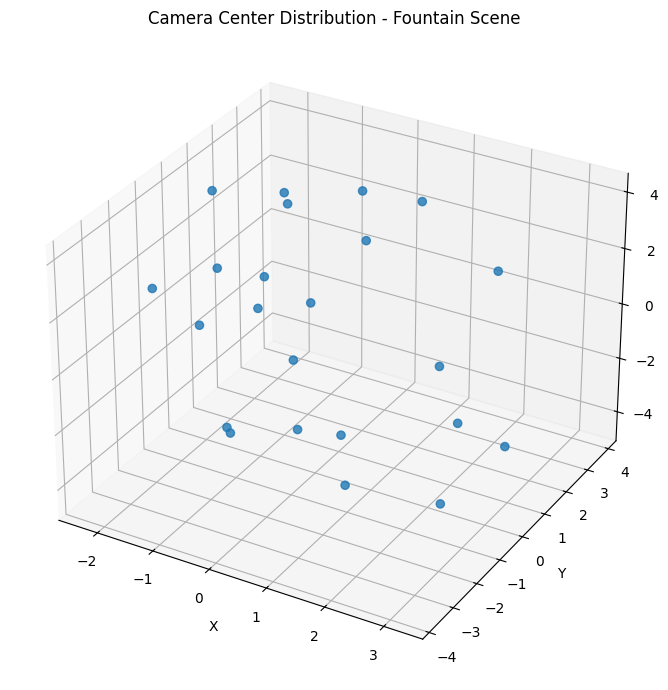

In [ ]:

if camera_df.empty:
    print("No valid camera poses found for the selected scene.")

else:
    fig = plt.figure(figsize=(10, 7))

    ax = fig.add_subplot(111, projection="3d")

    ax.scatter(
        camera_df["X"],
        camera_df["Y"],
        camera_df["Z"],
        s=35,
        alpha=0.8
    )

    ax.set_title("Camera Center Distribution - Fountain Scene")

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    plt.tight_layout()
    plt.show()



## Baseline: Feature-Based Image Clustering

### Objective

The objective of this baseline is to group images belonging to the same scene using local feature matching and graph-based clustering.

### Methodology

The proposed pipeline consists of:

1. **SIFT:** Extract local keypoints and descriptors from images.
2. **FLANN:** Match image features using Lowe's Ratio Test.
3. **Weighted Graph:** Represent images as nodes and feature matches as weighted edges.
4. **Louvain Community Detection:** Identify groups of images belonging to the same scene.
5. **Evaluation:** Measure clustering performance using Adjusted Rand Index (ARI), Pairwise Precision, Recall, and F1-score.

### Datasets

The experiments use two subsets from the Image Matching Challenge 2025 training dataset:

- **stairs:** 51 images, 2 ground-truth scenes.
- **imc2023_haiper:** 54 images, 3 ground-truth scenes.

Ground-truth labels are used only for evaluation, not for clustering.

In [ ]:

# Install the required libraries for the baseline
!pip -q install kaggle opencv-python-headless networkx scikit-learn pandas


In [ ]:

# Authenticate Kaggle using Google Colab Secrets
import os
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN")
os.environ["KAGGLE_API_TOKEN"] = token

print("Kaggle API token loaded successfully.")


SecretNotFoundError: Secret KAGGLE_API_TOKEN does not exist.

In [ ]:

# Download ground-truth labels from Kaggle
!kaggle competitions download -c image-matching-challenge-2025 -f train_labels.csv -p /content


In [ ]:

# Load the ground-truth labels
import pandas as pd

df = pd.read_csv("/content/train_labels.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

display(df.head())


In [ ]:

# Select the datasets used for baseline evaluation
selected_datasets = ["stairs", "imc2023_haiper"]

baseline_df = df[df["dataset"].isin(selected_datasets)].copy()

# Count images and ground-truth scenes
dataset_summary = baseline_df.groupby("dataset").agg(
    image_count=("image", "count"),
    scene_count=("scene", "nunique")
).reset_index()

display(dataset_summary)


In [ ]:

# Download the stairs dataset images
import os
import subprocess
import zipfile

stairs_df = baseline_df[baseline_df["dataset"] == "stairs"].copy()

stairs_folder = "/content/train/stairs"
os.makedirs(stairs_folder, exist_ok=True)

for image_name in stairs_df["image"]:
    image_path = os.path.join(stairs_folder, image_name)

    if os.path.exists(image_path):
        continue

    kaggle_file = f"train/stairs/{image_name}"

    subprocess.run([
        "kaggle", "competitions", "download",
        "-c", "image-matching-challenge-2025",
        "-f", kaggle_file,
        "-p", stairs_folder,
        "-q"
    ], check=True)

    zip_path = os.path.join(stairs_folder, image_name + ".zip")

    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(stairs_folder)
        os.remove(zip_path)

print("Stairs download step completed.")


In [ ]:

# Verify that all stairs images were downloaded
import os

stairs_image_names = stairs_df["image"].tolist()

expected_folder = "/content/train/stairs"
nested_folder = "/content/train/stairs/train/stairs"

# Check both possible extraction locations
for folder in [expected_folder, nested_folder]:
    found = sum(
        os.path.isfile(os.path.join(folder, name))
        for name in stairs_image_names
    )
    print(f"Folder: {folder}")
    print(f"Images found: {found} / {len(stairs_image_names)}")
    print()



In [ ]:

# Download the imc2023_haiper dataset images

haiper_df = baseline_df[
    baseline_df["dataset"] == "imc2023_haiper"
].copy()

haiper_folder = "/content/train/imc2023_haiper"
os.makedirs(haiper_folder, exist_ok=True)

for image_name in haiper_df["image"]:
    image_path = os.path.join(haiper_folder, image_name)
    nested_path = os.path.join(
        haiper_folder, "train", "imc2023_haiper", image_name
    )

    # Skip images that are already downloaded
    if os.path.isfile(image_path) or os.path.isfile(nested_path):
        continue

    kaggle_file = f"train/imc2023_haiper/{image_name}"

    subprocess.run([
        "kaggle", "competitions", "download",
        "-c", "image-matching-challenge-2025",
        "-f", kaggle_file,
        "-p", haiper_folder,
        "-q"
    ], check=True)

    zip_path = os.path.join(haiper_folder, image_name + ".zip")

    if os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(haiper_folder)
        os.remove(zip_path)

print("Haiper download step completed.")


In [ ]:

# Verify that all Haiper images were downloaded

haiper_image_names = haiper_df["image"].tolist()

expected_folder = "/content/train/imc2023_haiper"
nested_folder = "/content/train/imc2023_haiper/train/imc2023_haiper"

for folder in [expected_folder, nested_folder]:
    found = sum(
        os.path.isfile(os.path.join(folder, name))
        for name in haiper_image_names
    )

    print(f"Folder: {folder}")
    print(f"Images found: {found} / {len(haiper_image_names)}")
    print()


### SIFT Feature Extraction

We use Scale-Invariant Feature Transform (SIFT) to detect distinctive keypoints and compute local descriptors for each image.

The maximum number of features is set to 1,000. These descriptors are used in the subsequent image-matching stage.

In [ ]:

# Extract SIFT keypoints and descriptors from images
import cv2

def extract_sift_features(image_names, image_folder, nfeatures=1000):
    sift = cv2.SIFT_create(nfeatures=nfeatures)

    features = {}

    for name in image_names:
        image_path = os.path.join(image_folder, name)

        # Read the image in grayscale
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise FileNotFoundError(f"Image not found: {image_path}")

        # Detect keypoints and compute descriptors
        keypoints, descriptors = sift.detectAndCompute(image, None)

        features[name] = {
            "keypoints": keypoints,
            "descriptors": descriptors
        }

    return features

print("SIFT feature extraction function defined successfully.")


In [ ]:

# Extract SIFT features from the Stairs dataset

stairs_image_names = stairs_df["image"].tolist()
stairs_folder = "/content/train/stairs"

stairs_features = extract_sift_features(
    stairs_image_names,
    stairs_folder,
    nfeatures=1000
)

print("Images processed:", len(stairs_features))

# Show the number of keypoints in the first image
first_image = stairs_image_names[0]
print("First image:", first_image)
print("Keypoints detected:", len(stairs_features[first_image]["keypoints"]))


### FLANN Feature Matching

SIFT descriptors are matched using FLANN with a KD-tree index. Lowe's Ratio Test (threshold = 0.75) is applied to filter ambiguous matches.

For the Stairs dataset, 1,275 image pairs were compared, and 419 pairs had at least 20 good matches. These pairs are candidates for graph edges.

In [ ]:

# Match SIFT descriptors using FLANN and Lowe's Ratio Test
from itertools import combinations

def match_sift_features(image_names, features, ratio=0.75):

    # Set a random seed for more reproducible matching
    cv2.setRNGSeed(42)

    # FLANN parameters for SIFT descriptors
    index_params = dict(algorithm=1, trees=5)
    search_params = dict(checks=50)

    flann = cv2.FlannBasedMatcher(index_params, search_params)

    pair_results = []

    # Compare every unique pair of images
    for name1, name2 in combinations(image_names, 2):

        des1 = features[name1]["descriptors"]
        des2 = features[name2]["descriptors"]

        good_matches = []

        if des1 is not None and des2 is not None and len(des2) >= 2:

            matches = flann.knnMatch(des1, des2, k=2)

            # Lowe's Ratio Test
            for pair in matches:
                if len(pair) == 2:
                    m, n = pair

                    if m.distance < ratio * n.distance:
                        good_matches.append(m)

        pair_results.append({
            "image1": name1,
            "image2": name2,
            "good_matches": len(good_matches)
        })

    return pd.DataFrame(pair_results)

print("FLANN feature matching function defined successfully.")


In [ ]:

# Match all image pairs in the Stairs dataset

stairs_pairs_df = match_sift_features(
    stairs_image_names,
    stairs_features,
    ratio=0.75
)

print("Total image pairs:", len(stairs_pairs_df))
print("Pairs with at least 20 good matches:",
      (stairs_pairs_df["good_matches"] >= 20).sum())

display(stairs_pairs_df.head())


### Graph Construction and Louvain Clustering

Each image is represented as a node in an undirected graph. An edge is created between two images when they have at least 20 good SIFT matches. Edge weights correspond to the number of good matches.

We apply weighted Louvain community detection to group visually related images into clusters without using ground-truth scene labels.

In [ ]:

# Construct a weighted graph and detect communities using Louvain
import networkx as nx

def cluster_images(image_names, pairs_df, min_matches=20, resolution=1.0, seed=42):

    # Create an undirected graph
    G = nx.Graph()

    # Add every image as a node
    G.add_nodes_from(image_names)

    # Connect images with sufficient feature matches
    for _, row in pairs_df.iterrows():

        if row["good_matches"] >= min_matches:
            G.add_edge(
                row["image1"],
                row["image2"],
                weight=float(row["good_matches"])
            )

    # Detect communities using weighted Louvain clustering
    clusters = nx.community.louvain_communities(
        G,
        weight="weight",
        resolution=resolution,
        seed=seed
    )

    return G, clusters

print("Weighted Louvain clustering function defined successfully.")


In [ ]:

# Apply weighted Louvain clustering to the Stairs dataset

stairs_graph, stairs_clusters = cluster_images(
    stairs_image_names,
    stairs_pairs_df,
    min_matches=20,
    resolution=1.0,
    seed=42
)

print("Number of images:", stairs_graph.number_of_nodes())
print("Number of graph edges:", stairs_graph.number_of_edges())
print("Number of clusters:", len(stairs_clusters))
print("Cluster sizes:", sorted(len(cluster) for cluster in stairs_clusters))


### Evaluation Metrics

We evaluate the predicted image clusters against the ground-truth scene labels using the following metrics:

- **Adjusted Rand Index (ARI):** Measures agreement between predicted and true clusters, adjusted for chance.
- **Pairwise Precision:** Measures the proportion of predicted same-scene image pairs that are correct.
- **Pairwise Recall:** Measures the proportion of actual same-scene pairs identified by the model.
- **Pairwise F1-score:** The harmonic mean of pairwise precision and recall.

Ground-truth labels are used only during evaluation.

In [ ]:

# Evaluate image clustering using ground-truth scene labels
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import precision_recall_fscore_support

def evaluate_clustering(clusters, image_names, scene_map):

    # Assign a predicted cluster ID to each image
    predicted_map = {}

    for cluster_id, cluster in enumerate(clusters):
        for name in cluster:
            predicted_map[name] = cluster_id

    # Prepare true and predicted cluster labels
    true_labels = [scene_map[name] for name in image_names]
    pred_labels = [predicted_map[name] for name in image_names]

    # Calculate Adjusted Rand Index
    ari = adjusted_rand_score(true_labels, pred_labels)

    # Compare every unique image pair
    y_true = []
    y_pred = []

    for name1, name2 in combinations(image_names, 2):

        # 1 means both images belong to the same scene
        y_true.append(int(scene_map[name1] == scene_map[name2]))

        # 1 means both images are assigned to the same cluster
        y_pred.append(int(predicted_map[name1] == predicted_map[name2]))

    # Calculate pairwise classification metrics
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    return {
        "ARI": round(ari, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "Pairwise F1": round(f1, 4)
    }

print("Clustering evaluation function defined successfully.")


In [ ]:

# Evaluate weighted Louvain clustering on the Stairs dataset

# Map each image to its ground-truth scene
stairs_scene_map = dict(
    zip(stairs_df["image"], stairs_df["scene"])
)

# Calculate evaluation metrics
stairs_metrics = evaluate_clustering(
    stairs_clusters,
    stairs_image_names,
    stairs_scene_map
)

print("Stairs Baseline Evaluation Results")
print("----------------------------------")

for metric, value in stairs_metrics.items():
    print(f"{metric}: {value:.4f}")


In [ ]:

# Prepare the Haiper dataset for baseline evaluation

haiper_image_names = haiper_df["image"].tolist()
haiper_folder = "/content/train/imc2023_haiper"

haiper_scene_map = dict(
    zip(haiper_df["image"], haiper_df["scene"])
)

print("Haiper images:", len(haiper_image_names))
print("Ground-truth scenes:", haiper_df["scene"].nunique())
print("Image folder:", haiper_folder)


In [ ]:

# Extract SIFT features from the Haiper dataset

haiper_features = extract_sift_features(
    haiper_image_names,
    haiper_folder,
    nfeatures=1000
)

print("Images processed:", len(haiper_features))

# Check keypoints detected in the first image
first_image = haiper_image_names[0]

print("First image:", first_image)
print(
    "Keypoints detected:",
    len(haiper_features[first_image]["keypoints"])
)


In [ ]:

# Match all image pairs in the Haiper dataset

haiper_pairs_df = match_sift_features(
    haiper_image_names,
    haiper_features,
    ratio=0.75
)

print("Total image pairs:", len(haiper_pairs_df))

print(
    "Pairs with at least 20 good matches:",
    (haiper_pairs_df["good_matches"] >= 20).sum()
)

display(haiper_pairs_df.head())


In [ ]:

# Apply weighted Louvain clustering to the Haiper dataset

haiper_graph, haiper_clusters = cluster_images(
    haiper_image_names,
    haiper_pairs_df,
    min_matches=20,
    resolution=1.0,
    seed=42
)

print("Number of images:", haiper_graph.number_of_nodes())
print("Number of graph edges:", haiper_graph.number_of_edges())
print("Number of clusters:", len(haiper_clusters))
print("Cluster sizes:", sorted(len(cluster) for cluster in haiper_clusters))


In [ ]:

# Evaluate weighted Louvain clustering on the Haiper dataset

haiper_metrics = evaluate_clustering(
    haiper_clusters,
    haiper_image_names,
    haiper_scene_map
)

print("Haiper Baseline Evaluation Results")
print("----------------------------------")

for metric, value in haiper_metrics.items():
    print(f"{metric}: {value:.4f}")


## Experimental Results

We evaluated the SIFT + FLANN + Weighted Louvain baseline on two training subsets using the same parameters.

The Stairs dataset contains 51 images from 2 ground-truth scenes, while the Haiper dataset contains 54 images from 3 scenes.

The evaluation compares predicted clusters with ground-truth labels using ARI, Pairwise Precision, Recall, and F1-score.

In [ ]:

# Compare baseline results across both datasets

results_df = pd.DataFrame([
    {
        "Dataset": "Stairs",
        "Images": len(stairs_image_names),
        "True Scenes": stairs_df["scene"].nunique(),
        "Predicted Clusters": len(stairs_clusters),
        **stairs_metrics
    },
    {
        "Dataset": "Haiper",
        "Images": len(haiper_image_names),
        "True Scenes": haiper_df["scene"].nunique(),
        "Predicted Clusters": len(haiper_clusters),
        **haiper_metrics
    }
])

display(results_df)


In [ ]:

# Analyze the composition of predicted Haiper clusters

cluster_rows = []

for cluster_id, cluster in enumerate(haiper_clusters):
    for image_name in cluster:
        cluster_rows.append({
            "Predicted Cluster": cluster_id,
            "True Scene": haiper_scene_map[image_name]
        })

cluster_df = pd.DataFrame(cluster_rows)

cluster_composition = pd.crosstab(
    cluster_df["Predicted Cluster"],
    cluster_df["True Scene"]
)

display(cluster_composition)


## Discussion and Limitations

The SIFT + FLANN + Weighted Louvain baseline achieved an ARI of **0.4559** on Stairs and **0.6650** on Haiper.

On Stairs, the algorithm produced 6 clusters despite the dataset containing only 2 ground-truth scenes, indicating over-segmentation.

On Haiper, the algorithm correctly grouped all 23 Fountain images but merged the 15 Bike and 16 Chairs images into a single cluster. This explains the perfect pairwise recall (1.0000) alongside lower precision (0.6657).

These results highlight a limitation of feature-match-based graph clustering: visually similar images from different scenes can create misleading graph connections.

Potential improvements include geometric verification using RANSAC and more robust edge-selection strategies.

## Conclusion

This baseline demonstrates how SIFT feature extraction, FLANN matching, and weighted Louvain community detection can be combined for unsupervised image clustering.

The method achieved a Pairwise F1-score of **0.6888** on Stairs and **0.7993** on Haiper. However, the results also reveal over-segmentation and incorrect merging of visually related scenes.

Overall, the approach provides a useful reference point for future improvements, particularly through geometric verification and more reliable graph construction.

## Baseline 2 — ORB + BFMatcher + Graph Clustering

### Objective

This baseline uses ORB (Oriented FAST and Rotated BRIEF) to extract local image features and BFMatcher (Brute-Force Matcher) to identify visual correspondences between image pairs.

Images are represented as nodes in a graph, and sufficiently similar image pairs are connected by edges. Weighted Louvain community detection is then applied to the graph to obtain predicted image clusters.

The method is evaluated on the same Stairs and Haiper training subsets used in the SIFT + FLANN + Weighted Louvain baseline, enabling a consistent comparison.

Ground-truth scene labels are used only for evaluation.

In [ ]:

# Extract ORB keypoints and descriptors from images

import cv2
import os

def extract_orb_features(image_names, image_folder, nfeatures=1000):

    orb = cv2.ORB_create(nfeatures=nfeatures)

    features = {}

    for name in image_names:

        image_path = os.path.join(image_folder, name)

        # Read the image in grayscale
        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise FileNotFoundError(f"Image not found: {image_path}")

        # Detect keypoints and compute ORB descriptors
        keypoints, descriptors = orb.detectAndCompute(image, None)

        features[name] = {
            "keypoints": keypoints,
            "descriptors": descriptors
        }

    return features


print("ORB feature extraction function defined successfully.")


In [ ]:

# Match ORB descriptors using BFMatcher and Lowe's Ratio Test

from itertools import combinations

def match_orb_features(image_names, features, ratio=0.75):

    # BFMatcher with Hamming distance for ORB binary descriptors
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

    pair_results = []

    # Compare every unique pair of images
    for name1, name2 in combinations(image_names, 2):

        des1 = features[name1]["descriptors"]
        des2 = features[name2]["descriptors"]

        good_matches = []

        if des1 is not None and des2 is not None and len(des2) >= 2:

            matches = bf.knnMatch(des1, des2, k=2)

            # Lowe's Ratio Test
            for pair in matches:
                if len(pair) == 2:
                    m, n = pair

                    if m.distance < ratio * n.distance:
                        good_matches.append(m)

        pair_results.append({
            "image1": name1,
            "image2": name2,
            "good_matches": len(good_matches)
        })

    return pd.DataFrame(pair_results)


print("ORB feature matching function defined successfully.")


In [ ]:

# Extract ORB features from the Stairs dataset

stairs_orb_features = extract_orb_features(
    stairs_image_names,
    stairs_folder,
    nfeatures=1000
)

print("Images processed:", len(stairs_orb_features))

first_image = stairs_image_names[0]

print("First image:", first_image)
print(
    "Keypoints detected:",
    len(stairs_orb_features[first_image]["keypoints"])
)


In [ ]:

# Extract ORB features from the Haiper dataset

haiper_orb_features = extract_orb_features(
    haiper_image_names,
    haiper_folder,
    nfeatures=1000
)

print("Images processed:", len(haiper_orb_features))

first_image = haiper_image_names[0]

print("First image:", first_image)
print(
    "Keypoints detected:",
    len(haiper_orb_features[first_image]["keypoints"])
)


In [ ]:

# Match ORB features across all Stairs image pairs

stairs_orb_pairs_df = match_orb_features(
    stairs_image_names,
    stairs_orb_features,
    ratio=0.75
)

print("Total image pairs:", len(stairs_orb_pairs_df))

print("\nORB matching statistics:")
display(stairs_orb_pairs_df["good_matches"].describe())

display(stairs_orb_pairs_df.head())


In [ ]:

# Analyze the number of strong ORB matches

print(
    "Pairs with at least 20 good matches:",
    (stairs_orb_pairs_df["good_matches"] >= 20).sum()
)

print("\nTop 10 matching image pairs:")

display(
    stairs_orb_pairs_df.sort_values(
        by="good_matches",
        ascending=False
    ).head(10)
)


In [ ]:

# Match ORB features across all Haiper image pairs

haiper_orb_pairs_df = match_orb_features(
    haiper_image_names,
    haiper_orb_features,
    ratio=0.75
)

print("Total image pairs:", len(haiper_orb_pairs_df))

print("\nORB matching statistics:")
display(haiper_orb_pairs_df["good_matches"].describe())

display(haiper_orb_pairs_df.head())


In [ ]:

# Analyze the number of strong ORB matches

print(
    "Pairs with at least 20 good matches:",
    (haiper_orb_pairs_df["good_matches"] >= 20).sum()
)

print("\nTop 10 matching image pairs:")

display(
    haiper_orb_pairs_df.sort_values(
        by="good_matches",
        ascending=False
    ).head(10)
)


In [ ]:

# Apply Weighted Louvain clustering to Stairs using ORB matches

stairs_orb_graph, stairs_orb_clusters = cluster_images(
    stairs_image_names,
    stairs_orb_pairs_df,
    min_matches=20,
    resolution=1.0,
    seed=42
)

print("Number of images:", stairs_orb_graph.number_of_nodes())
print("Number of graph edges:", stairs_orb_graph.number_of_edges())
print("Number of clusters:", len(stairs_orb_clusters))
print(
    "Cluster sizes:",
    sorted([len(cluster) for cluster in stairs_orb_clusters])
)


In [ ]:

# Apply Weighted Louvain clustering to Haiper using ORB matches

haiper_orb_graph, haiper_orb_clusters = cluster_images(
    haiper_image_names,
    haiper_orb_pairs_df,
    min_matches=20,
    resolution=1.0,
    seed=42
)

print("Number of images:", haiper_orb_graph.number_of_nodes())
print("Number of graph edges:", haiper_orb_graph.number_of_edges())
print("Number of clusters:", len(haiper_orb_clusters))
print(
    "Cluster sizes:",
    sorted([len(cluster) for cluster in haiper_orb_clusters])
)


In [ ]:

# Evaluate ORB clustering on the Haiper dataset

haiper_orb_metrics = evaluate_clustering(
    haiper_orb_clusters,
    haiper_image_names,
    haiper_scene_map
)

print("Haiper ORB Evaluation Results")
print("----------------------------------")
print("ARI:", round(haiper_orb_metrics["ARI"], 4))
print("Precision:", round(haiper_orb_metrics["Precision"], 4))
print("Recall:", round(haiper_orb_metrics["Recall"], 4))
print("Pairwise F1:", round(haiper_orb_metrics["Pairwise F1"], 4))


## SIFT vs ORB Baseline Comparison

We compare SIFT and ORB feature extraction methods using the same Weighted Louvain clustering algorithm on both datasets.

The results show that SIFT achieves higher ARI and Pairwise F1 scores than ORB on both datasets. ORB produces high precision but relatively low recall, indicating that it misses many images belonging to the same scene.

Overall, SIFT provides a stronger baseline for image clustering in this experiment.

In [ ]:
# Evaluate ORB clustering on the Stairs dataset first to define stairs_orb_metrics
stairs_orb_metrics = evaluate_clustering(
    stairs_orb_clusters,
    stairs_image_names,
    stairs_scene_map
)

# Compare SIFT and ORB baseline results
comparison_df = pd.DataFrame([
    {
        "Dataset": "Stairs",
        "Method": "SIFT",
        **stairs_metrics
    },
    {
        "Dataset": "Stairs",
        "Method": "ORB",
        **stairs_orb_metrics
    },
    {
        "Dataset": "Haiper",
        "Method": "SIFT",
        **haiper_metrics
    },
    {
        "Dataset": "Haiper",
        "Method": "ORB",
        **haiper_orb_metrics
    }
])

display(comparison_df.round(4))

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Prepare comparison data
datasets = ["Stairs", "Haiper"]

metrics_to_plot = ["ARI", "Pairwise F1"]

for metric in metrics_to_plot:

    x = np.arange(len(datasets))
    width = 0.35

    sift_values = [
        comparison_df[
            (comparison_df["Dataset"] == dataset) &
            (comparison_df["Method"] == "SIFT")
        ][metric].values[0]
        for dataset in datasets
    ]

    orb_values = [
        comparison_df[
            (comparison_df["Dataset"] == dataset) &
            (comparison_df["Method"] == "ORB")
        ][metric].values[0]
        for dataset in datasets
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(x - width/2, sift_values, width, label="SIFT")
    plt.bar(x + width/2, orb_values, width, label="ORB")

    plt.xticks(x, datasets)
    plt.ylabel(metric)
    plt.title(f"SIFT vs ORB - {metric} Comparison")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()


### Baseline Results: Graphical Comparison

The graphs show that SIFT outperforms ORB on both datasets in terms of ARI and Pairwise F1-score.

SIFT achieves an ARI of 0.4559 on Stairs and 0.6650 on Haiper, while ORB achieves 0.2329 and 0.1835, respectively.

Similarly, SIFT achieves higher Pairwise F1-scores on both datasets. These results suggest that SIFT provides more reliable feature matching for the image clustering task in our experiments.

Although ORB achieves perfect precision on Haiper, its low recall indicates that it misses many image pairs belonging to the same scene.